In [19]:
%matplotlib inline
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from lime.lime_tabular import LimeTabularExplainer
import shap
import matplotlib.pyplot as plt
import numpy as np

In [20]:
# Load the dataset
try:
    df = pd.read_csv("../../../Datasets/csv/UAVATTACK/jamming-merged-gps-only.csv")
except FileNotFoundError:
    print("Error: The file '../../../Datasets/excel/2dSpoofingDataset/GPS_Data_Simplified_2D_Feature_Map.xlsx' was not found.")
    print("Please make sure the path is correct.")
    exit()

In [21]:
feature_names = list(df.columns)
print("First 5 rows of the dataset:")
print(df.head())

First 5 rows of the dataset:
   timestamp      q[0]      q[1]      q[2]      q[3]  delta_q_reset[0]  \
0  332828103 -0.278094 -0.004139 -0.002317  0.960542          0.999999   
1  333003247 -0.278094 -0.004139 -0.002317  0.960542          0.999999   
2  333008246 -0.278094 -0.004139 -0.002317  0.960542          0.999999   
3  333013247 -0.278096 -0.004139 -0.002316  0.960542          0.999999   
4  333022041 -0.278098 -0.004136 -0.002315  0.960541          0.999999   

   delta_q_reset[1]  delta_q_reset[2]  delta_q_reset[3]  quat_reset_counter  \
0      5.520000e-10     -4.980000e-10          0.001079                   3   
1      5.520000e-10     -4.980000e-10          0.001079                   3   
2      5.520000e-10     -4.980000e-10          0.001079                   3   
3      5.520000e-10     -4.980000e-10          0.001079                   3   
4      5.520000e-10     -4.980000e-10          0.001079                   3   

   ...  v_z_valid  xy_reset_counter  z_reset_counte

In [22]:
feature_names.remove('label')
X = df[feature_names]
y = df['label']

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=100
)

In [24]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train model on scaled data
clf = LogisticRegression()
clf.fit(X_train_scaled, y_train)

LogisticRegression()

Intercept 0.16063720111924618
Prediction_local [-0.05245352]
Right: 1.4021431636958091e-05
Intercept 0.8393627988807539
Prediction_local [1.05245352]
Right: 0.999985978568363


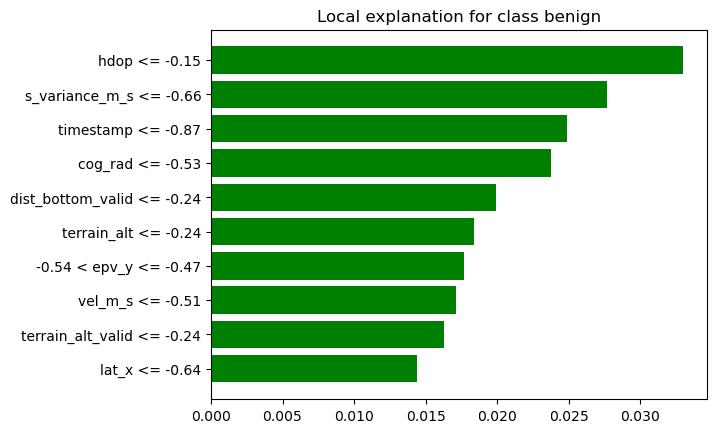

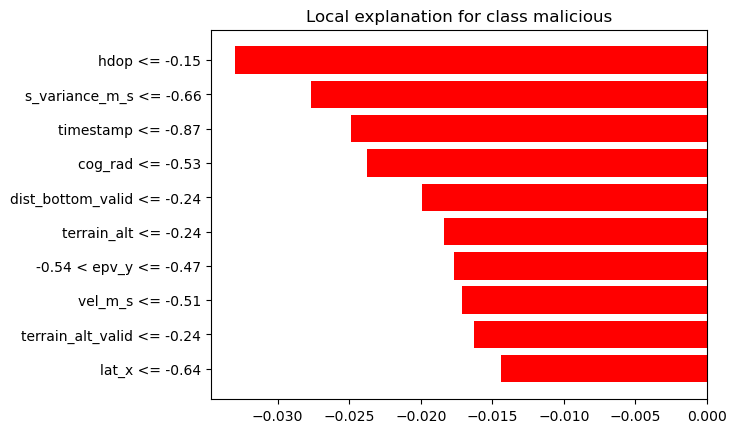

In [25]:
explainer = LimeTabularExplainer(
    training_data=X_train_scaled,
    training_labels=y_train,
    feature_names=feature_names,
    class_names=['benign', 'malicious'],
    kernel_width=3,
    verbose=True,
    mode='classification'
)
instance = X_test_scaled[0]
exp = explainer.explain_instance(instance, clf.predict_proba, top_labels=4)
for class_idx, class_name in enumerate(['benign', 'malicious']):
    fig = exp.as_pyplot_figure(label=class_idx)
    plt.show()
    fig.savefig(f"lime_explanation_{class_name}.png")
    plt.close(fig)

In [26]:
for feature, weight in exp.as_list():
    print(f"{feature}: {weight:.4f}")

hdop <= -0.15: -0.0330
s_variance_m_s <= -0.66: -0.0277
timestamp <= -0.87: -0.0249
cog_rad <= -0.53: -0.0238
dist_bottom_valid <= -0.24: -0.0199
terrain_alt <= -0.24: -0.0184
-0.54 < epv_y <= -0.47: -0.0177
vel_m_s <= -0.51: -0.0171
terrain_alt_valid <= -0.24: -0.0163
lat_x <= -0.64: -0.0144


In [27]:
print(y.unique())

['benign' 'malicious']


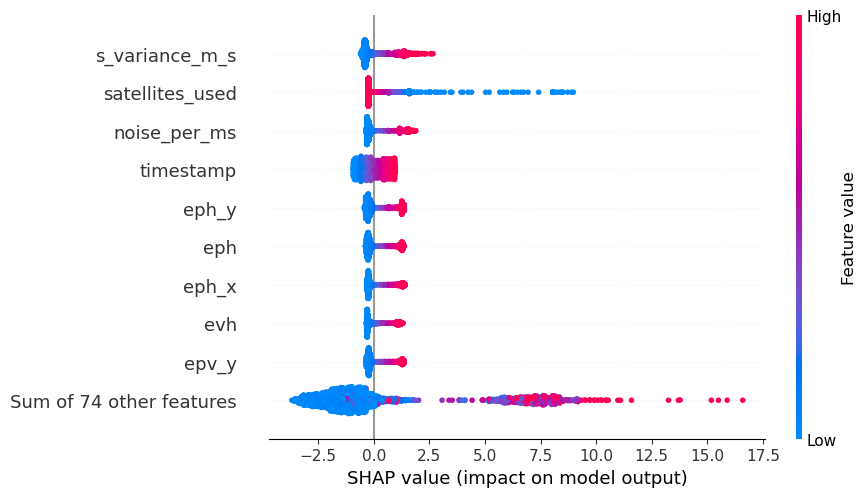

In [28]:
shap.initjs()

shap_explainer = shap.Explainer(clf, X_train_scaled, feature_names=feature_names)
shap_values = shap_explainer(X_test_scaled)

shap.plots.beeswarm(shap_values)

In [29]:
# Get mean absolute SHAP values for each feature
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)

top_n = 10  # change this to however many top features you want
top_features_idx = np.argsort(mean_abs_shap)[::-1][:top_n]

# Print the feature names and their importance
print("Top features:")
for idx in top_features_idx:
    print(f"{feature_names[idx]}: {mean_abs_shap[idx]:.4f}")

Top features:
s_variance_m_s: 0.6007
satellites_used: 0.5279
noise_per_ms: 0.4948
timestamp: 0.4805
eph_y: 0.4460
eph: 0.4419
eph_x: 0.4397
evh: 0.4373
epv_y: 0.4251
vel_m_s: 0.4142
